# R2-A2-S8S9 · Informe de resultados de tratamiento de imagen
**Percepción Computacional — Especialización en Inteligencia Artificial, Universidad de Cundinamarca**  
**Autor:** Juan Pablo Cristancho Tula

**Objeto de estudio:** estuche de carga de un micrófono inalámbrico Hollyland (negro mate, logotipo gris y texto impreso).

**Flujo de trabajo:** Diagnóstico → Problema identificado → Decisión técnica → Tratamiento → Evaluación.

## 0. Preparación del entorno
En Colab, sube las cinco fotos a la carpeta `imagenes/` con los nombres `referencia.jpg`, `oscura.jpg`, `desenfocada.jpg`, `fondo.jpg` y `angulo.jpg` (también están en este repositorio).

In [1]:
import os
os.makedirs("imagenes", exist_ok=True)
# En Colab:
# !pip install -q opencv-python-headless numpy matplotlib pandas
# from google.colab import files
# files.upload()   # sube las 5 fotos y muévelas a imagenes/

## 1. Librerías y configuración

In [2]:
import argparse
import json
import os

import cv2
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

CONDICIONES = {
    "referencia": "Referencia",
    "oscura": "Baja iluminación",
    "desenfocada": "Desenfoque",
    "fondo": "Fondo complejo",
    "angulo": "Otra perspectiva",
}
ANCHO_ANALISIS = 1024          # ancho comun para comparar metricas
UMBRAL_OSCURO = 50             # pixel subexpuesto
UMBRAL_SATURADO = 205          # pixel sobreexpuesto
CANNY_BAJO, CANNY_ALTO = 50, 150

GAMMA_MIN = 0.40               # limite inferior de gamma (evita lavar el negro del estuche)
CLAHE_CLIP, CLAHE_TILES = 2.0, (8, 8)
NLM_H = 5                      # fuerza del filtro de medias no locales (luminancia)

AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#52514e"

## 2. Carga de imágenes

In [3]:
def cargar(ruta):
    img = cv2.imdecode(np.fromfile(ruta, dtype=np.uint8), cv2.IMREAD_COLOR)
    if img is None:
        raise IOError(f"No se pudo leer {ruta}")
    return img


def redimensionar(img, ancho=ANCHO_ANALISIS):
    h, w = img.shape[:2]
    escala = ancho / w
    interp = cv2.INTER_AREA if escala < 1 else cv2.INTER_CUBIC
    return cv2.resize(img, (ancho, int(round(h * escala))), interpolation=interp)

## 3. Métricas de calidad

In [4]:
def ruido_immerkaer(gris):
    h, w = gris.shape
    k = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float64)
    r = cv2.filter2D(gris.astype(np.float64), -1, k)
    return float(np.sqrt(np.pi / 2) * np.abs(r[1:-1, 1:-1]).sum() / (6 * (w - 2) * (h - 2)))


def entropia(gris):
    hist = cv2.calcHist([gris], [0], None, [256], [0, 256]).ravel()
    p = hist / hist.sum()
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())


def metricas(img):
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    b = cv2.Canny(g, CANNY_BAJO, CANNY_ALTO)
    return {
        "brillo": float(g.mean()),
        "contraste": float(g.std()),
        "nitidez": float(cv2.Laplacian(g, cv2.CV_64F).var()),
        "ruido": ruido_immerkaer(g),
        "entropia": entropia(g),
        "pct_oscuros": float((g < UMBRAL_OSCURO).mean() * 100),
        "pct_saturados": float((g > UMBRAL_SATURADO).mean() * 100),
        "bordes": float((b > 0).mean() * 100),
    }


def diagnosticar(nombre, m, ref):
    p = []
    if m["brillo"] < 0.6 * ref["brillo"]:
        p.append("subexposición")
    if m["contraste"] < 0.75 * ref["contraste"]:
        p.append("bajo contraste")
    if m["nitidez"] < 0.5 * ref["nitidez"] and nombre != "oscura":
        p.append("pérdida de nitidez")
    if nombre == "fondo":
        p.append("distractores en el fondo")
    if nombre == "angulo":
        p.append("cambio de perspectiva")
    if nombre == "referencia":
        return "Ninguno (línea base)", "Sí"
    criticos = {"subexposición", "bajo contraste", "pérdida de nitidez"}
    return ", ".join(p).capitalize(), ("No" if criticos & set(p) else "Condicional")

## 4. Tratamientos (alternativas y propuesta)

In [5]:
def ajuste_lineal(img, alpha=1.6, beta=10):
    return cv2.convertScaleAbs(img, alpha=alpha, beta=beta)


def ecualizacion_global(img):
    l, a, b = cv2.split(cv2.cvtColor(img, cv2.COLOR_BGR2LAB))
    return cv2.cvtColor(cv2.merge((cv2.equalizeHist(l), a, b)), cv2.COLOR_LAB2BGR)


def gamma_adaptativa(l):
    media = max(float(l.mean()) / 255.0, 1e-3)
    return float(np.clip(np.log(0.5) / np.log(media), GAMMA_MIN, 1.0))


def aplicar_gamma(l, g):
    lut = (np.power(np.arange(256) / 255.0, g) * 255).round().astype(np.uint8)
    return cv2.LUT(l, lut)


def gamma_clahe(img, usar_gamma=True):
    l, a, b = cv2.split(cv2.cvtColor(img, cv2.COLOR_BGR2LAB))
    if usar_gamma:
        l = aplicar_gamma(l, gamma_adaptativa(l))
    l = cv2.createCLAHE(clipLimit=CLAHE_CLIP, tileGridSize=CLAHE_TILES).apply(l)
    return cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2BGR)


def tratamiento_propuesto(img):
    """Gamma adaptativa (L) -> CLAHE (L) -> medias no locales sobre L."""
    realzada = gamma_clahe(img, usar_gamma=True)
    l, a, b = cv2.split(cv2.cvtColor(realzada, cv2.COLOR_BGR2LAB))
    l = cv2.fastNlMeansDenoising(l, None, h=NLM_H, templateWindowSize=7, searchWindowSize=21)
    return cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2BGR)


def gamma_clahe_bilateral(img):
    return cv2.bilateralFilter(gamma_clahe(img), 5, 25, 5)

## 5. Figuras

In [6]:
def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def estilo(ax):
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.tick_params(colors=GRIS, labelsize=8)
    ax.grid(axis="y", color="#e6e5e0", linewidth=0.6)
    ax.set_axisbelow(True)


def fig_conjunto(imgs, met, ruta):
    fig, ejes = plt.subplots(2, 3, figsize=(13, 5.6))
    ejes.ravel()[-1].axis("off")
    for ax, (n, im) in zip(ejes.ravel(), imgs.items()):
        m = met[n]
        ax.imshow(rgb(im)); ax.set_title(CONDICIONES[n], fontsize=11)
        ax.set_xlabel(f"Brillo {m['brillo']:.1f} | Contraste {m['contraste']:.1f} | Nitidez {m['nitidez']:.1f}",
                      fontsize=8, color=GRIS)
        ax.set_xticks([]); ax.set_yticks([])
    fig.tight_layout(); fig.savefig(ruta, dpi=170); plt.close(fig)


def fig_histogramas(imgs, ruta):
    fig, ejes = plt.subplots(2, 3, figsize=(12, 5.4), sharey=True)
    ejes.ravel()[-1].axis("off")
    for ax, (n, im) in zip(ejes.ravel(), imgs.items()):
        g = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
        h = cv2.calcHist([g], [0], None, [256], [0, 256]).ravel(); h = h / h.sum() * 100
        ax.fill_between(np.arange(256), h, color=AZUL, alpha=0.3, linewidth=0)
        ax.plot(h, color=AZUL, linewidth=1.2)
        ax.set_title(CONDICIONES[n], fontsize=10); ax.set_xlim(0, 255)
        ax.set_xlabel("Intensidad", fontsize=8, color=GRIS); estilo(ax)
    for ax in ejes[:, 0]:
        ax.set_ylabel("% de píxeles", fontsize=8, color=GRIS)
    fig.tight_layout(); fig.savefig(ruta, dpi=170); plt.close(fig)


def fig_variantes(variantes, ruta):
    fig, ejes = plt.subplots(2, 3, figsize=(13, 5.4))
    for ax, (t, im) in zip(ejes.ravel(), variantes.items()):
        ax.imshow(rgb(im)); ax.set_title(t, fontsize=10); ax.axis("off")
    fig.tight_layout(); fig.savefig(ruta, dpi=170); plt.close(fig)


def fig_antes_despues(orig, trat, ruta):
    fig, ejes = plt.subplots(1, 2, figsize=(12, 3.2))
    for ax, im, t in zip(ejes, (orig, trat), ("Antes (baja iluminación)", "Después (tratamiento propuesto)")):
        ax.imshow(rgb(im)); ax.set_title(t, fontsize=10); ax.axis("off")
    fig.tight_layout(); fig.savefig(ruta, dpi=170); plt.close(fig)


def fig_hist_cdf(orig, trat, ref, ruta):
    fig, (ha, ca) = plt.subplots(1, 2, figsize=(11, 3.4))
    for im, et, col, ls in ((orig, "Antes", AZUL, "-"), (trat, "Después", NARANJA, "-"), (ref, "Referencia", GRIS, "--")):
        g = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
        h = cv2.calcHist([g], [0], None, [256], [0, 256]).ravel(); h = h / h.sum()
        ha.plot(h * 100, color=col, linewidth=1.5, linestyle=ls, label=et)
        ca.plot(np.cumsum(h) * 100, color=col, linewidth=1.8, linestyle=ls, label=et)
    ha.set_title("Histograma de intensidad", fontsize=10); ha.set_ylabel("% de píxeles", fontsize=8, color=GRIS)
    ca.set_title("Distribución acumulada (CDF)", fontsize=10); ca.set_ylabel("% acumulado", fontsize=8, color=GRIS)
    for ax in (ha, ca):
        ax.set_xlim(0, 255); ax.set_xlabel("Intensidad", fontsize=8, color=GRIS)
        ax.legend(frameon=False, fontsize=8); estilo(ax)
    fig.tight_layout(); fig.savefig(ruta, dpi=170); plt.close(fig)


def fig_bordes(orig, trat, ref, ruta):
    fig, ejes = plt.subplots(1, 3, figsize=(13, 2.6))
    for ax, im, t in zip(ejes, (orig, trat, ref), ("Bordes - original oscura", "Bordes - tratada", "Bordes - referencia")):
        ax.imshow(cv2.Canny(cv2.cvtColor(im, cv2.COLOR_BGR2GRAY), CANNY_BAJO, CANNY_ALTO), cmap="gray")
        ax.set_title(t, fontsize=10); ax.axis("off")
    fig.tight_layout(); fig.savefig(ruta, dpi=170); plt.close(fig)


def fig_zoom(orig, trat, ruta):
    """Recorte ampliado del logotipo para ver ruido y detalle."""
    h, w = orig.shape[:2]
    y0, y1, x0, x1 = int(h * 0.22), int(h * 0.52), int(w * 0.38), int(w * 0.62)
    fig, ejes = plt.subplots(1, 3, figsize=(12, 3.2))
    ref_bil = gamma_clahe_bilateral(orig)
    for ax, im, t in zip(ejes, (orig, gamma_clahe(orig), trat),
                         ("Original", "Gamma + CLAHE (sin filtrar)", "Propuesta (Gamma + CLAHE + NLM)")):
        ax.imshow(rgb(im[y0:y1, x0:x1])); ax.set_title(t, fontsize=10); ax.axis("off")
    fig.tight_layout(); fig.savefig(ruta, dpi=170); plt.close(fig)

## 6. Programa principal

In [7]:
def formatos(img, carpeta):
    rj, rp = os.path.join(carpeta, "comparacion.jpg"), os.path.join(carpeta, "comparacion.png")
    cv2.imwrite(rj, img, [cv2.IMWRITE_JPEG_QUALITY, 90]); cv2.imwrite(rp, img)
    h, w = img.shape[:2]
    return {"resolucion": f"{w} × {h}", "jpg_kb": os.path.getsize(rj) / 1024,
            "png_kb": os.path.getsize(rp) / 1024, "psnr_jpg": float(cv2.PSNR(img, cv2.imread(rj)))}


def ejecutar(cimg, csal):
    os.makedirs(csal, exist_ok=True)
    originales, imgs = {}, {}
    for n in CONDICIONES:
        ruta = next(os.path.join(cimg, n + e) for e in (".jpg", ".jpeg", ".png") if os.path.isfile(os.path.join(cimg, n + e)))
        originales[n] = cargar(ruta)
        imgs[n] = redimensionar(originales[n])
    met = {n: metricas(im) for n, im in imgs.items()}
    for n in met:
        h, w, c = originales[n].shape
        ruta = next(os.path.join(cimg, n + e) for e in (".jpg", ".jpeg", ".png") if os.path.isfile(os.path.join(cimg, n + e)))
        met[n].update({"ancho": w, "alto": h, "canales": c, "kb": os.path.getsize(ruta) / 1024})
        met[n]["problema"], met[n]["adecuada"] = diagnosticar(n, met[n], met["referencia"])
    fmt = formatos(imgs["referencia"], csal)

    o = imgs["oscura"]
    variantes = {
        "Original (oscura)": o,
        "Ajuste lineal α=1.6, β=10": ajuste_lineal(o),
        "Ecualización global": ecualizacion_global(o),
        "Solo CLAHE": gamma_clahe(o, usar_gamma=False),
        "Gamma + CLAHE + bilateral": gamma_clahe_bilateral(o),
        "Gamma + CLAHE + NLM (propuesta)": tratamiento_propuesto(o),
    }
    trat = {k: metricas(v) for k, v in variantes.items()}
    trat["Gamma + CLAHE"] = metricas(gamma_clahe(o))
    t = variantes["Gamma + CLAHE + NLM (propuesta)"]
    cv2.imwrite(os.path.join(csal, "oscura_tratada.png"), t)

    fig_conjunto(imgs, met, os.path.join(csal, "fig1_conjunto.png"))
    fig_histogramas(imgs, os.path.join(csal, "fig2_histogramas.png"))
    fig_variantes(variantes, os.path.join(csal, "fig4_variantes.png"))
    fig_antes_despues(o, t, os.path.join(csal, "fig5_antes_despues.png"))
    fig_hist_cdf(o, t, imgs["referencia"], os.path.join(csal, "fig6_hist_cdf.png"))
    fig_bordes(o, t, imgs["referencia"], os.path.join(csal, "fig7_bordes.png"))
    fig_zoom(o, t, os.path.join(csal, "fig8_zoom.png"))

    res = {"metricas": met, "formatos": fmt, "tratamiento": trat,
           "gamma": gamma_adaptativa(cv2.cvtColor(o, cv2.COLOR_BGR2LAB)[:, :, 0])}
    with open(os.path.join(csal, "metricas.json"), "w", encoding="utf-8") as f:
        json.dump(res, f, ensure_ascii=False, indent=2)
    return res

## 7. Ejecución y tabla de diagnóstico

In [8]:
import pandas as pd
r = ejecutar('imagenes', 'resultados')
cols = ['brillo','contraste','nitidez','ruido','entropia','pct_oscuros','bordes','ancho','alto','canales','kb','problema','adecuada']
tabla = pd.DataFrame(r['metricas']).T[cols]
tabla.index = [CONDICIONES[n] for n in tabla.index]
tabla

,brillo,contraste,nitidez,ruido,entropia,pct_oscuros,bordes,ancho,alto,canales,kb,problema,adecuada
Referencia,144.286899,37.174534,222.105743,1.120968,6.59716,2.242377,3.941142,2576,1190,3,355.724609,Ninguno (línea base),Sí
Baja iluminación,76.714171,25.680524,44.761345,0.49306,6.104707,17.468081,0.694743,2576,1190,3,189.658203,"Subexposición, bajo contraste",No
Desenfoque,79.760036,26.397144,90.51136,0.650237,6.187554,16.779326,1.435733,2576,1190,3,236.260742,"Subexposición, bajo contraste, pérdida de nitidez",No
Fondo complejo,122.130614,49.919998,70.205998,1.053903,7.331795,8.799386,1.658505,2576,1190,3,328.574219,"Pérdida de nitidez, distractores en el fondo",No
Otra perspectiva,145.555778,38.59906,306.679212,1.565327,6.59729,5.25403,10.762214,2576,1190,3,446.867188,Cambio de perspectiva,Condicional


## 8. Comparación de alternativas sobre la imagen oscura

In [9]:
pd.DataFrame(r['tratamiento']).T[['brillo','contraste','nitidez','ruido','pct_oscuros','pct_saturados','bordes']].astype(float).round(2)

,brillo,contraste,nitidez,ruido,pct_oscuros,pct_saturados,bordes
Original (oscura),76.71,25.68,44.76,0.49,17.47,0.00,0.69
"Ajuste lineal α=1.6, β=10",132.74,41.11,115.63,0.82,6.95,0.21,2.30
Ecualización global,125.40,72.55,710.55,2.44,20.27,18.24,17.52
Solo CLAHE,88.74,30.62,200.06,1.35,15.09,0.00,7.41
Gamma + CLAHE + bilateral,120.35,34.03,125.28,0.66,6.91,0.02,4.29
Gamma + CLAHE + NLM (propuesta),120.47,33.94,102.76,0.38,6.88,0.02,3.88
Gamma + CLAHE,120.46,34.26,186.87,1.35,7.02,0.02,6.39


## 9. Evidencias visuales

fig1_conjunto


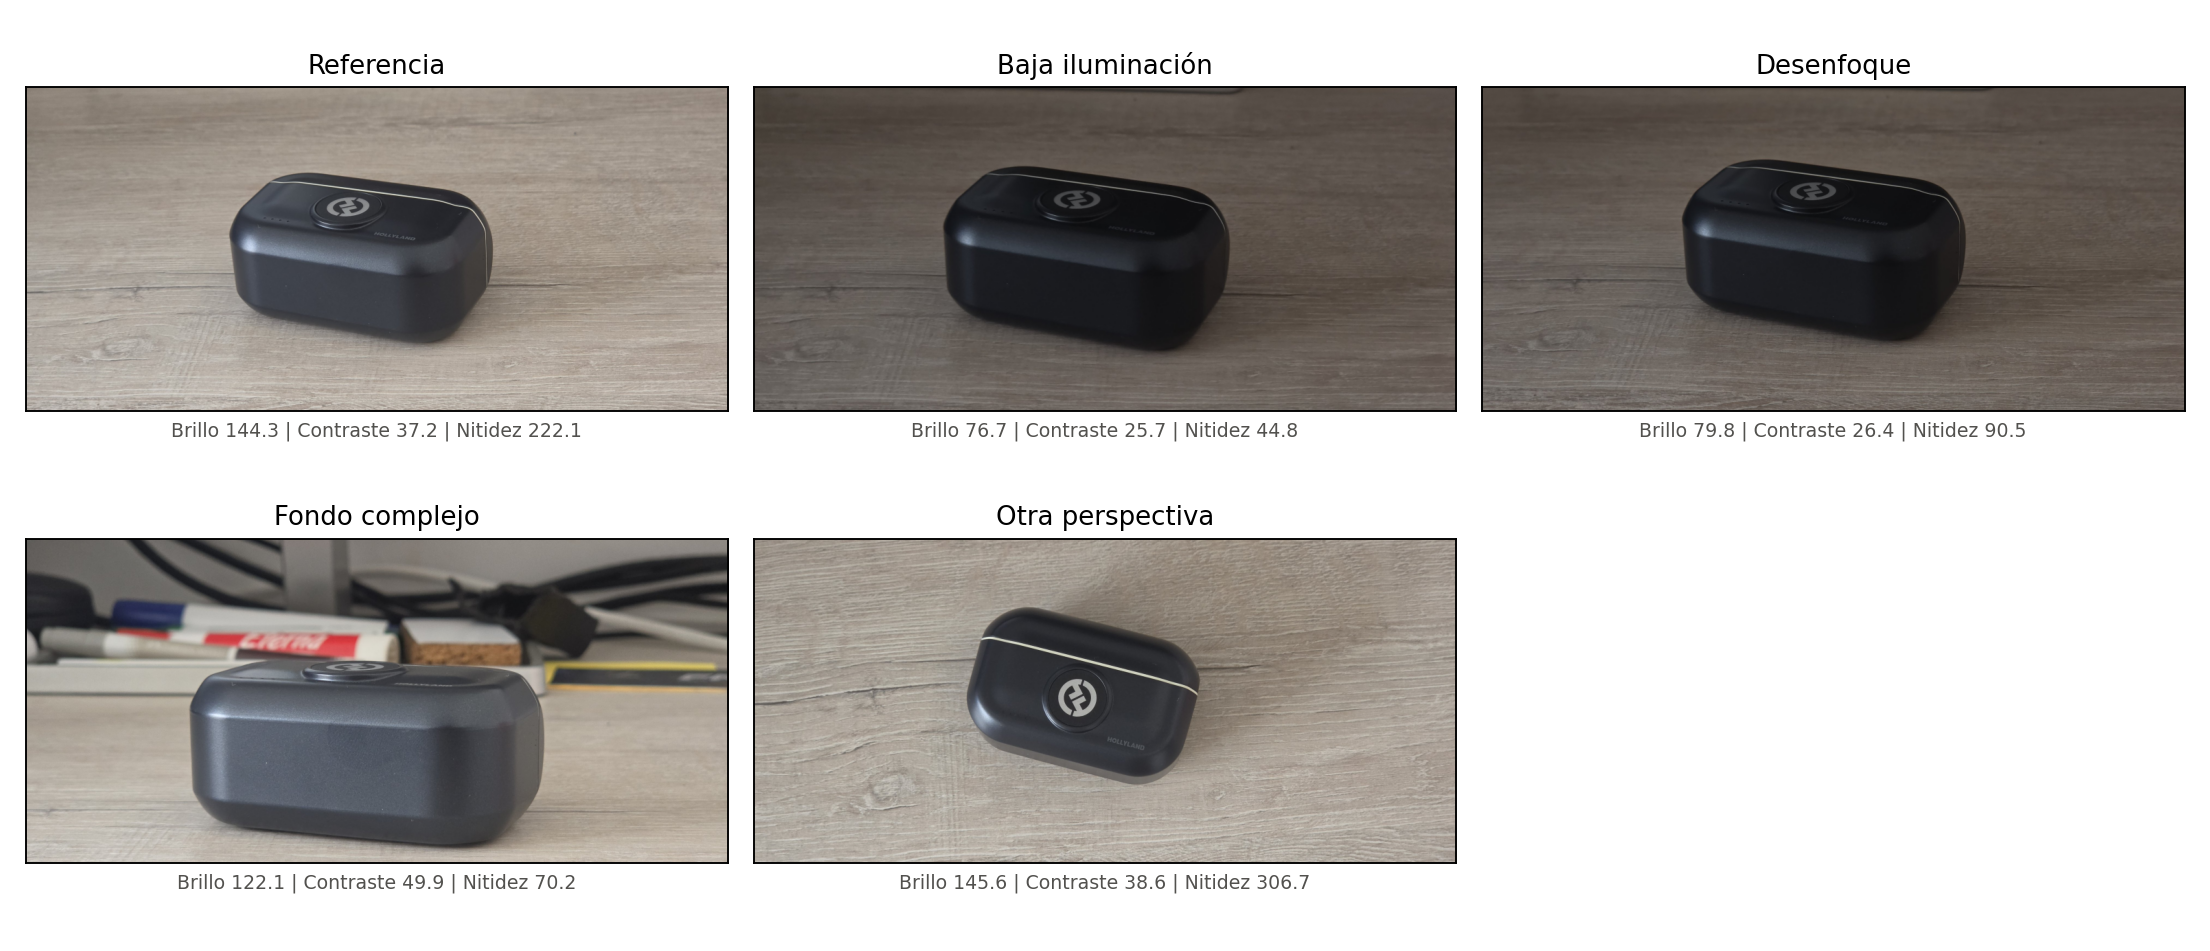

fig2_histogramas


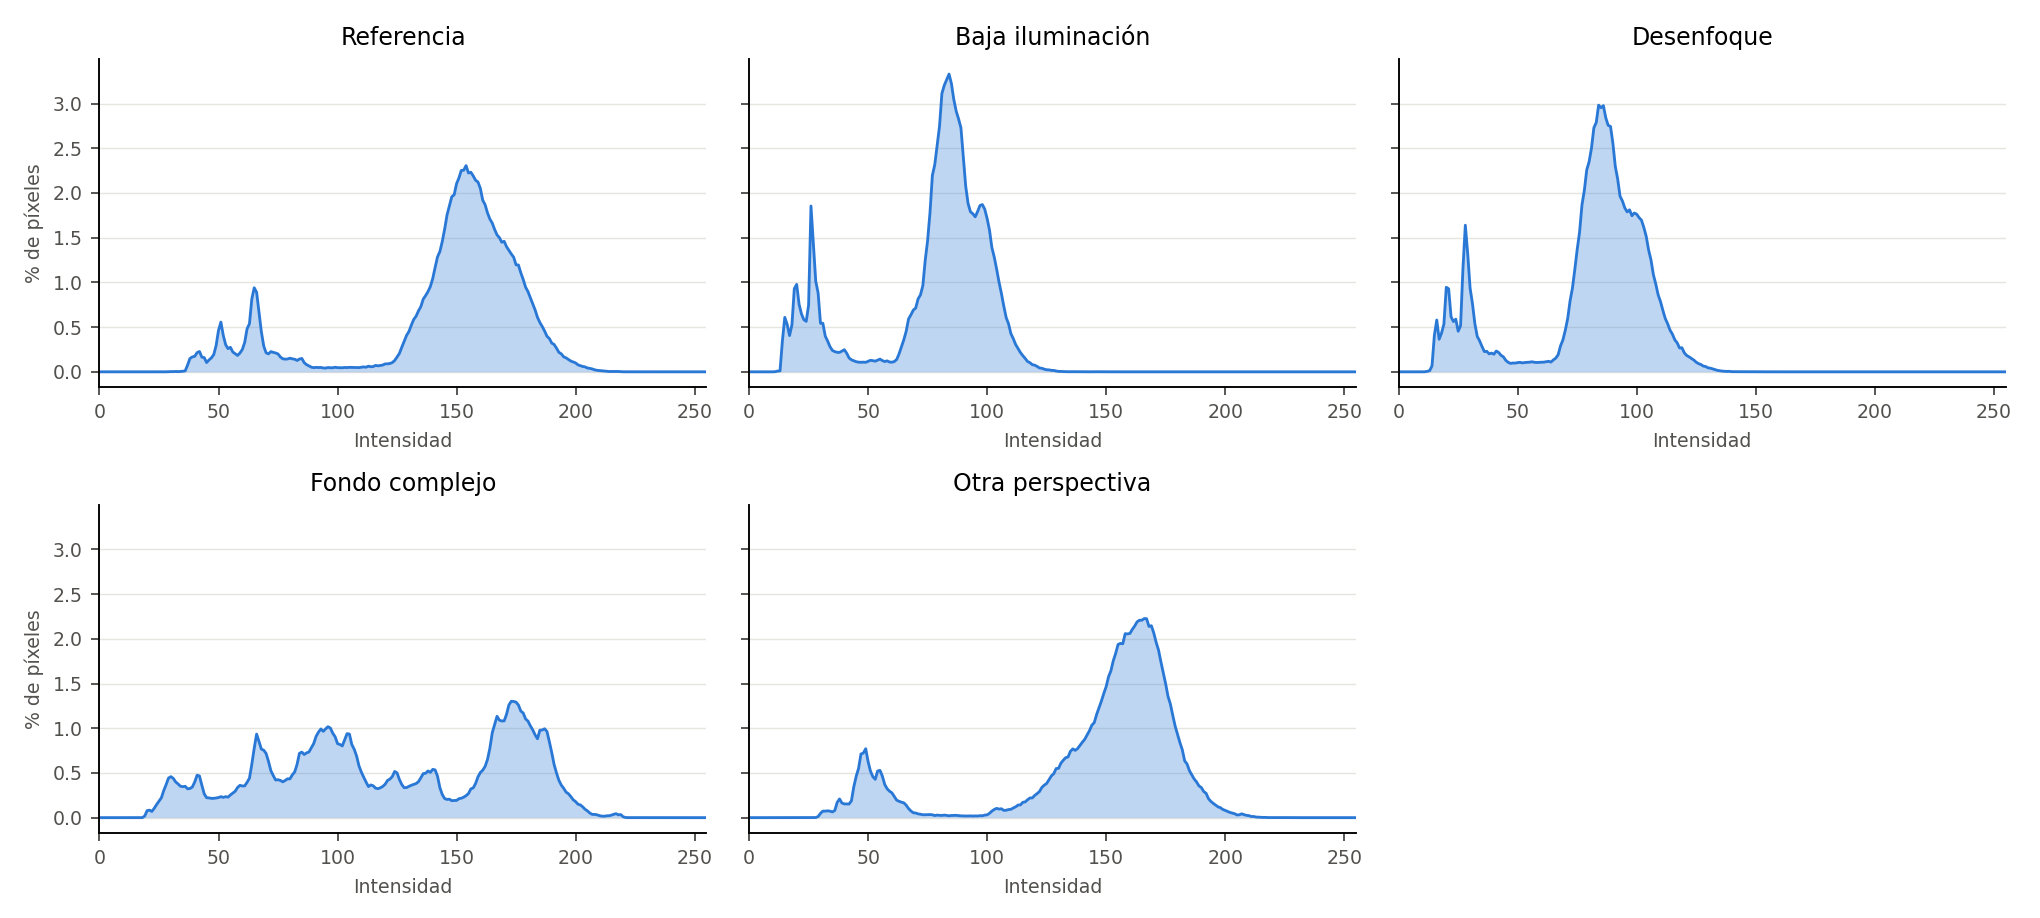

fig4_variantes


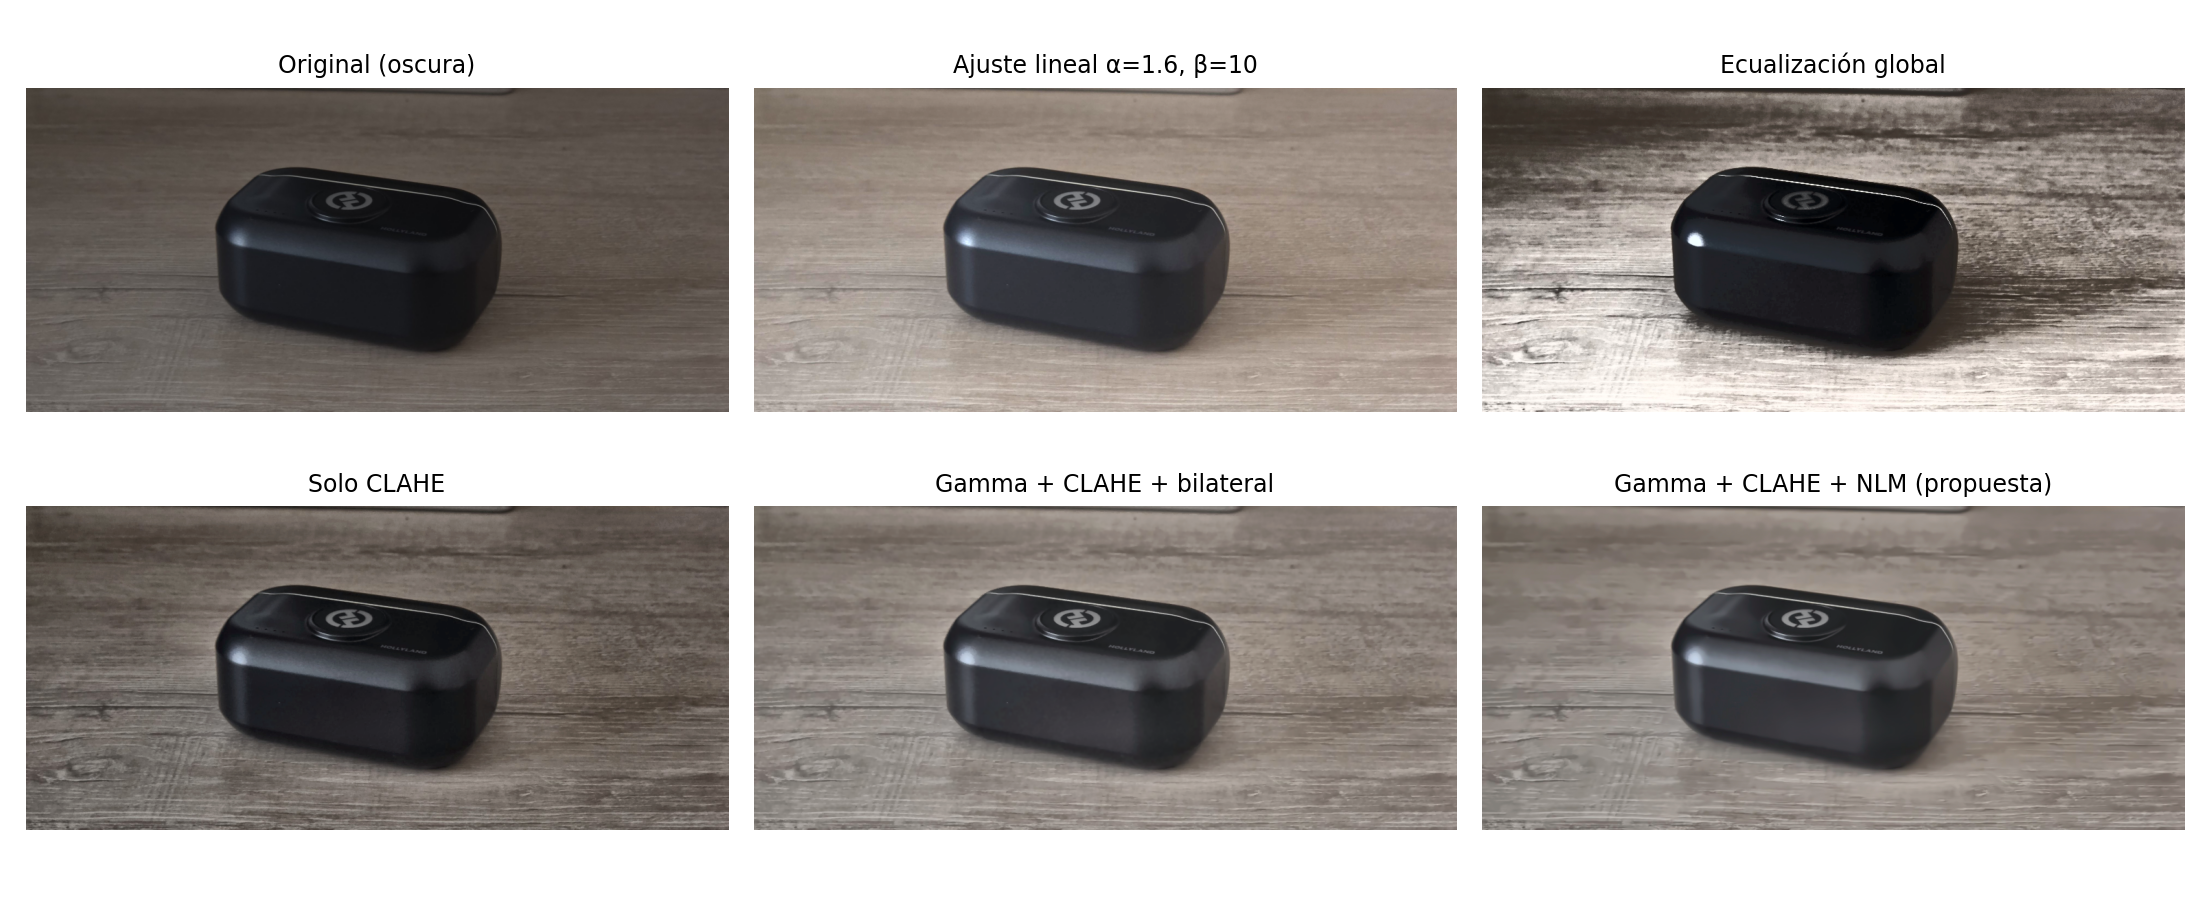

fig5_antes_despues


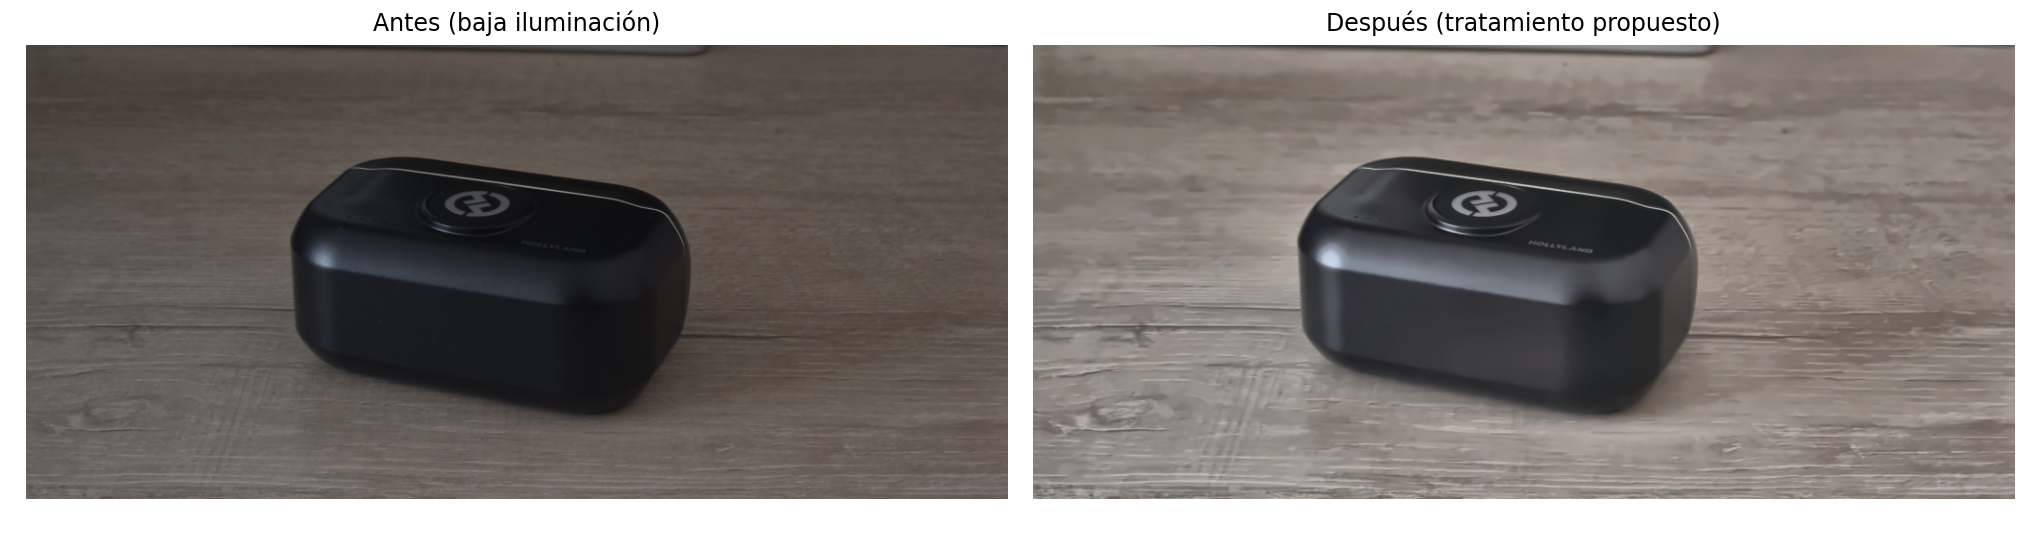

fig6_hist_cdf


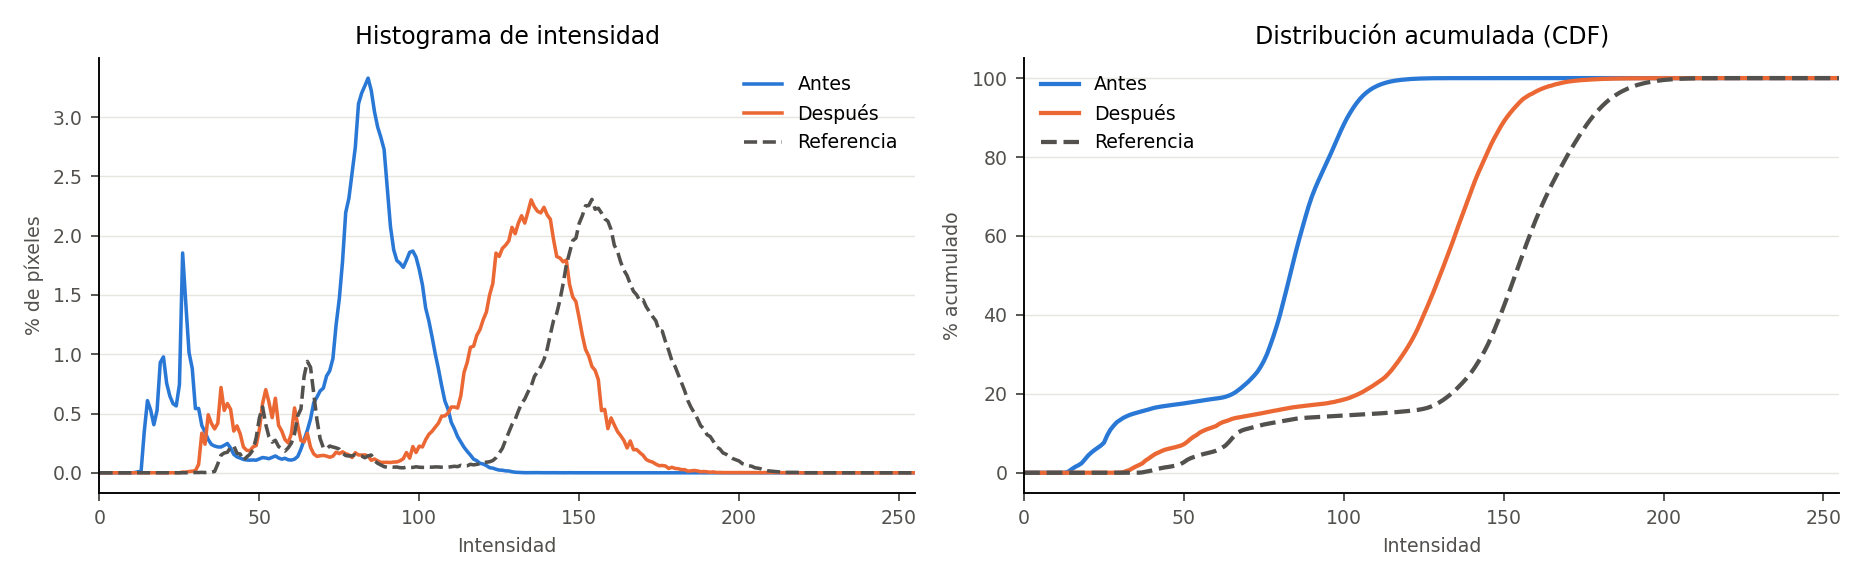

fig7_bordes


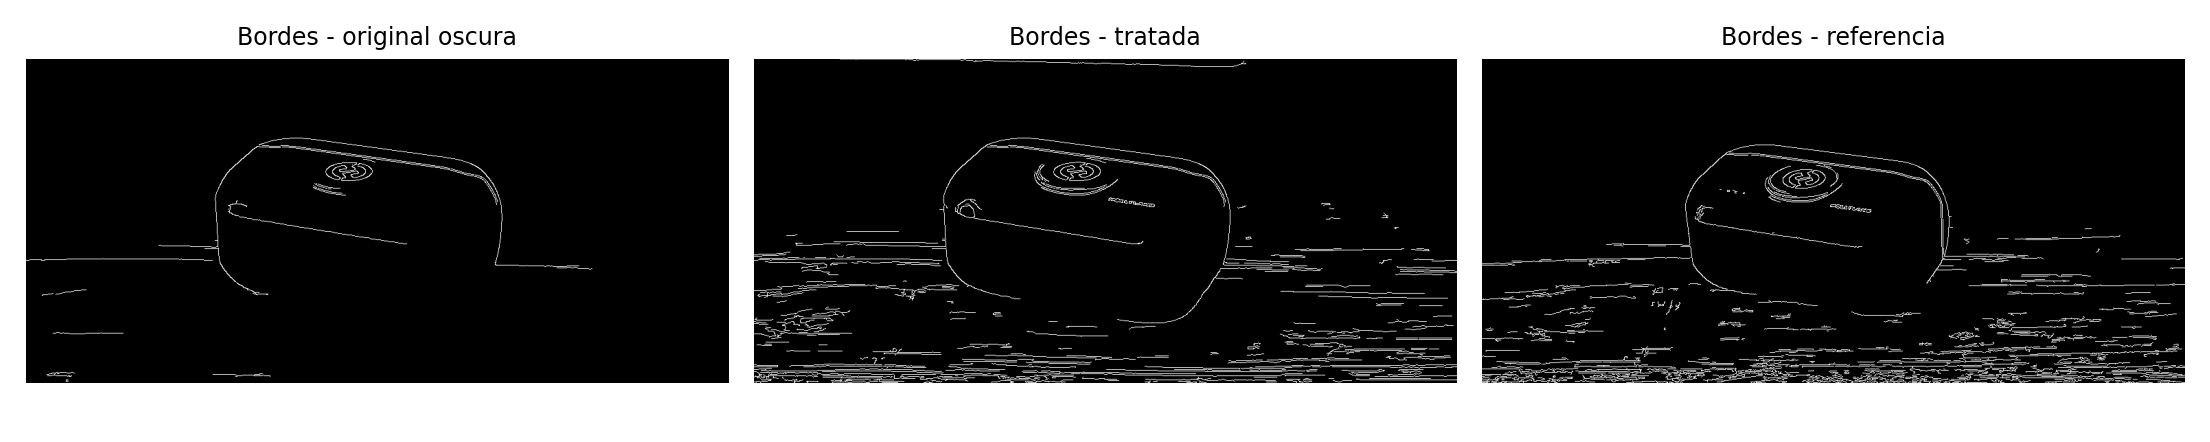

fig8_zoom


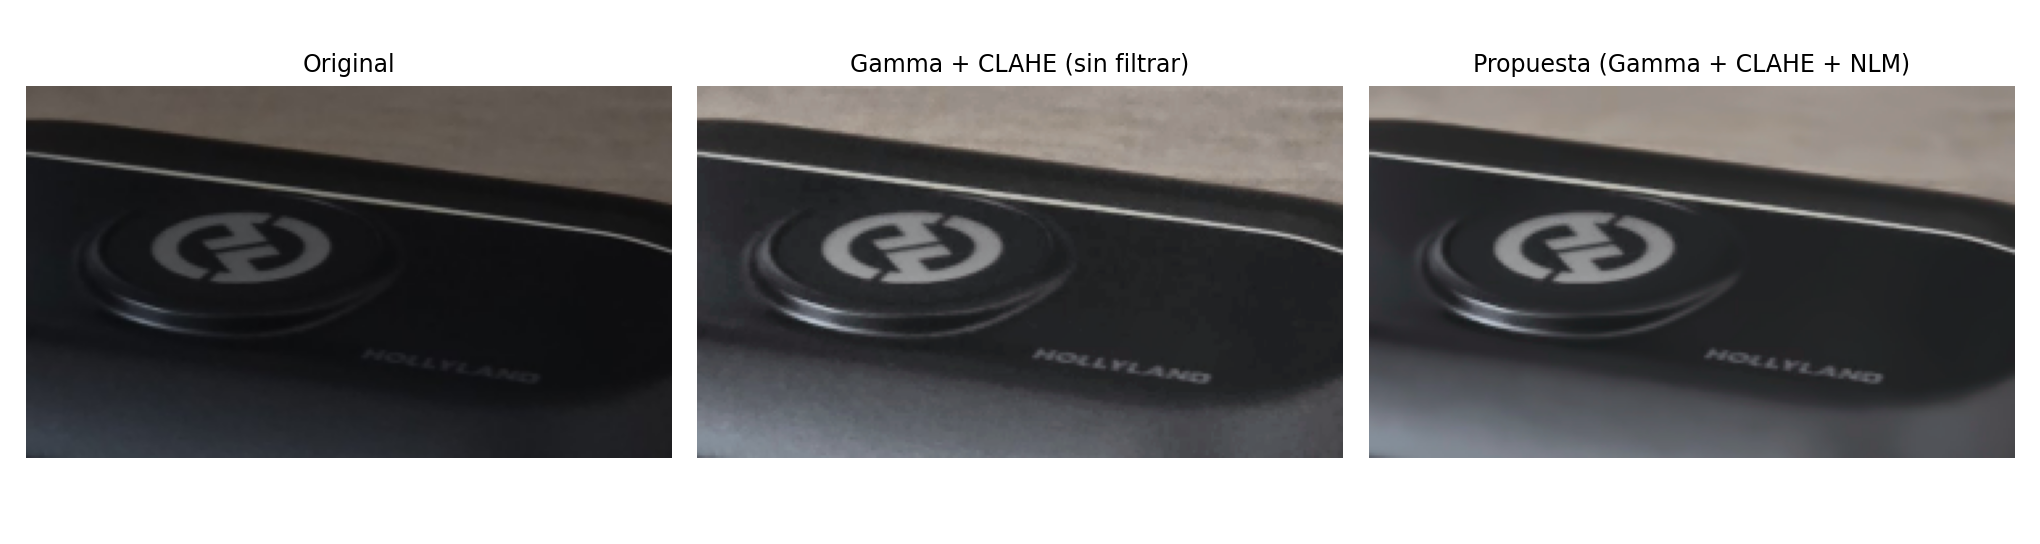

In [10]:
from IPython.display import Image, display
for f in ['fig1_conjunto','fig2_histogramas','fig4_variantes','fig5_antes_despues','fig6_hist_cdf','fig7_bordes','fig8_zoom']:
    print(f); display(Image(f'resultados/{f}.png'))

## 10. Formato de almacenamiento (JPG vs PNG)

In [11]:
r['formatos']

{'resolucion': '1024 × 473',
 'jpg_kb': 83.474609375,
 'png_kb': 557.318359375,
 'psnr_jpg': 43.167391541063594}